In [1]:
import tangram
import scanpy as sc

import numpy as np
import gzip
import os
os.chdir("/nfs/data3/mopitas/")
from scipy.sparse import csr_matrix, coo_matrix
import anndata as ad
import pandas as pd
from shapely.geometry import Polygon
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import muon as mu
from scipy.io import mmread
from muon import atac as ac
import seaborn as sns
from pathlib import Path
import sys


In [2]:
project_root = None
current_dir = Path.cwd()
print(current_dir)
# Check current dir and its parents for a 'src' subdirectory
for parent in [current_dir] + list(current_dir.parents):
    if (parent / 'luisthesis/analysis').is_dir():
        project_root = os.path.join(parent,'luisthesis')
        break
        print(project_root)
if project_root and str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

    print(f"Added {project_root} to sys.path")
elif not project_root:
    print("Warning: Could not automatically find project root. Imports from src.* might fail.")
    print("Please ensure you run this notebook from the project root or add it to sys.path manually.")

try:
    # Import config module and genome loading function from the src package
    from analysis import genetic_annotation as ga
    
    print("Successfully imported config and load_gencode_gtf_genes from src")
except ImportError as e:
    print(e)
    print("Please check your project structure and ensure src/__init__.py exists.")


/nfs/data3/mopitas
Added /nfs/data3/mopitas/luisthesis to sys.path
Successfully imported config and load_gencode_gtf_genes from src


In [3]:
# --- Configuration ---

# Add project root to sys.path (important for notebooks to find 'src')
# This is a common pattern in notebooks to ensure imports work
# Find project root by searching for the directory containing 'src'
project_root = None
current_dir = Path.cwd()
# Check current dir and its parents for a 'src' subdirectory
for parent in [current_dir] + list(current_dir.parents):
    if (parent / 'src').is_dir():
        project_root = parent
        break

if project_root and str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print(f"Added {project_root} to sys.path")
elif not project_root:
    print("Warning: Could not automatically find project root. Imports from src.* might fail.")
    print("Please ensure you run this notebook from the project root or add it to sys.path manually.")

# Define the path to the specific mouse brain data subdirectory
# Use the DATA_DIR from config and join with the subdirectory name
# Since config.DATA_DIR is already a Path object, use the / operator
MOUSE_BRAIN_DATA_DIR = "luisthesis/data/shareseq/"
H5AD_DIR = "luisthesis/data/shareseq/"

# Now define your file paths using the MOUSE_BRAIN_DATA_DIR variable
RNA_COUNTS_FILE = MOUSE_BRAIN_DATA_DIR+"/GSM4156610_brain.rna.counts.txt.gz"
ATAC_COUNTS_FILE = MOUSE_BRAIN_DATA_DIR+"/GSM4156599_brain.counts.txt.gz"
ATAC_PEAKS_FILE = MOUSE_BRAIN_DATA_DIR+"/GSM4156599_brain.peaks.bed.gz"
CELLTYPE_FILE = MOUSE_BRAIN_DATA_DIR+"/GSM4156599_brain_celltype.txt.gz"
ATAC_BARCODES_FILE = MOUSE_BRAIN_DATA_DIR+"/GSM4156599_brain.barcodes.txt.gz"
ATAC_FRAGMENTS_FILE = MOUSE_BRAIN_DATA_DIR+"/GSM4156599_brain.atac.fragments.sorted.bed.gz"
ATAC_UNSORTED_FRAGMENTS_FILE = MOUSE_BRAIN_DATA_DIR+"GSM4156599_brain.atac.fragments.bed.gz"

Added / to sys.path


In [4]:
# Load the cell type/pairing file
# This file links ATAC and RNA barcodes for the paired cells (3293 cells)

df_celltype = pd.read_csv(CELLTYPE_FILE, sep='\t')

In [5]:
df_celltype.head()

,atac.bc,rna.bc,celltype
0,R1.01.R2.04.R3.55.P1.32,R1.01.R2.04.R3.55.P1.40,EN07
1,R1.01.R2.05.R3.35.P1.32,R1.01.R2.05.R3.35.P1.40,P1
2,R1.01.R2.08.R3.45.P1.31,R1.01.R2.08.R3.45.P1.39,IN01
3,R1.01.R2.08.R3.78.P1.31,R1.01.R2.08.R3.78.P1.39,EN02
4,R1.01.R2.09.R3.52.P1.32,R1.01.R2.09.R3.52.P1.40,IN02


In [6]:
# Organize the dataframe to have rna.bc as the index
df_celltype = df_celltype.set_index('rna.bc')

In [7]:
df_celltype.head()

,atac.bc,celltype
rna.bc,,
R1.01.R2.04.R3.55.P1.40,R1.01.R2.04.R3.55.P1.32,EN07
R1.01.R2.05.R3.35.P1.40,R1.01.R2.05.R3.35.P1.32,P1
R1.01.R2.08.R3.45.P1.39,R1.01.R2.08.R3.45.P1.31,IN01
R1.01.R2.08.R3.78.P1.39,R1.01.R2.08.R3.78.P1.31,EN02
R1.01.R2.09.R3.52.P1.40,R1.01.R2.09.R3.52.P1.32,IN02


In [8]:
# Get the list of paired RNA barcodes to use as common cell IDs
common_cell_ids = df_celltype.index.tolist()

In [9]:
common_cell_ids[:5]  # Display the first 5 common cell IDs

['R1.01.R2.04.R3.55.P1.40',
 'R1.01.R2.05.R3.35.P1.40',
 'R1.01.R2.08.R3.45.P1.39',
 'R1.01.R2.08.R3.78.P1.39',
 'R1.01.R2.09.R3.52.P1.40']

In [10]:
# Load RNA counts matrix (Genes x Cells)

df_rna_counts = pd.read_csv(RNA_COUNTS_FILE, sep='\t', index_col=0)

In [11]:
# Clean the column names (cell barcodes) in the RNA counts DataFrame
# They use commas (,) but the celltype file uses periods (.)
# Replace commas with periods to match the common_cell_ids format

df_rna_counts.columns = df_rna_counts.columns.str.replace(',', '.', regex=False)

In [12]:
df_rna_counts.head()

,R1.01.R2.01.R3.24.P1.40,R1.01.R2.04.R3.55.P1.40,R1.01.R2.05.R3.35.P1.40,R1.01.R2.08.R3.24.P1.40,R1.01.R2.08.R3.45.P1.39,R1.01.R2.08.R3.78.P1.39,R1.01.R2.09.R3.52.P1.40,R1.01.R2.17.R3.52.P1.39,R1.01.R2.18.R3.91.P1.39,R1.01.R2.20.R3.36.P1.39,...,R1.96.R2.76.R3.90.P1.40,R1.96.R2.77.R3.30.P1.40,R1.96.R2.77.R3.57.P1.40,R1.96.R2.79.R3.15.P1.39,R1.96.R2.82.R3.84.P1.39,R1.96.R2.84.R3.71.P1.39,R1.96.R2.85.R3.91.P1.39,R1.96.R2.88.R3.65.P1.39,R1.96.R2.90.R3.91.P1.40,R1.96.R2.91.R3.15.P1.39
gene,,,,,,,,,,,,,,,,,,,,,
0610007P14Rik,0,0,0,0,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
0610009B22Rik,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
0610009L18Rik,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
0610009O20Rik,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
0610010F05Rik,2,0,1,0,0,0,2,0,0,2,...,0,0,0,0,0,2,3,0,2,1


In [13]:
# Subset the RNA counts DataFrame to keep only the columns (cells) that are in our paired set
# This aligns the RNA data to the 3293 paired cells
# .reindex(columns=...) will select the columns and also handle cases where a barcode might be missing (inserts NaNs)
# We use .dropna(axis=1) to remove any columns that were entirely NaN if reindexing failed
df_rna_subset = df_rna_counts.reindex(columns=common_cell_ids).dropna(axis=1)

In [14]:
# Verify that the columns now exactly match the common cell IDs
if list(df_rna_subset.columns) != common_cell_ids:
     print("Error: Subsetting RNA counts failed to exactly match common cell IDs!")
     # Handle error - critical for alignment
else:
     print("RNA counts columns successfully subsetted and aligned to common cell IDs.")

RNA counts columns successfully subsetted and aligned to common cell IDs.


In [15]:
# Transpose the DataFrame to be Cells x Genes for AnnData
df_rna_transposed = df_rna_subset.T.copy() # Use .T for transpose and .copy()

In [16]:
# Create the AnnData object for RNA
# X: The transposed counts matrix (Paired_Cells x Genes)
# obs: Observation metadata (cells). Index should be the common cell IDs.
# var: Variable metadata (genes). Index should be the gene IDs.
adata_rna = ad.AnnData(
    X=df_rna_transposed,
    obs=pd.DataFrame(index=df_rna_transposed.index), # Use transposed index (common cell IDs) for obs names
    var=pd.DataFrame(index=df_rna_transposed.columns) # Use transposed columns (gene IDs) for var names
)

In [17]:
# Add cell type annotations to adata_rna.obs
# The index of adata_rna.obs is common_cell_ids (rna.bc)
# The index of df_celltype is also rna.bc
# Merge df_celltype (keeping only the 'celltype' column) into adata_rna.obs
adata_rna.obs = adata_rna.obs.merge(df_celltype[['celltype']], left_index=True, right_index=True, how='left')

In [18]:
adata_rna.obs.head()

,celltype
R1.01.R2.04.R3.55.P1.40,EN07
R1.01.R2.05.R3.35.P1.40,P1
R1.01.R2.08.R3.45.P1.39,IN01
R1.01.R2.08.R3.78.P1.39,EN02
R1.01.R2.09.R3.52.P1.40,IN02


In [19]:
adata_rna.var_names.str.startswith("Mt-").sum()

0

In [20]:
sc.pp.calculate_qc_metrics(
    adata_rna, inplace=True, log1p=True
)

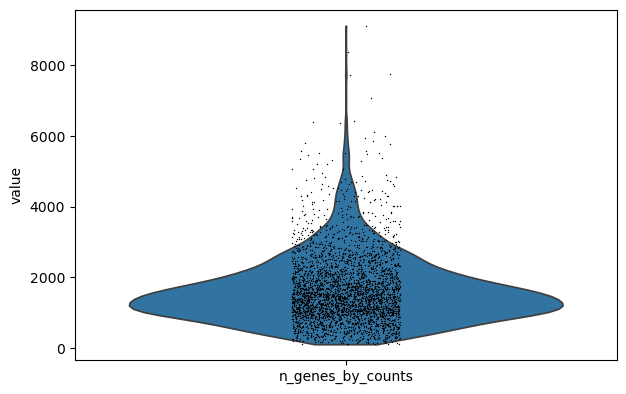

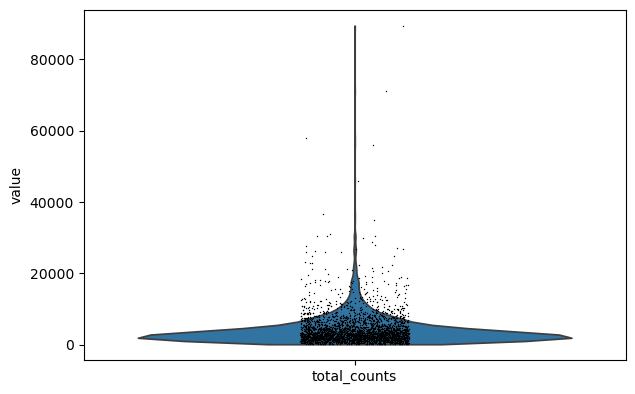

(None, None)

In [21]:
sc.pl.violin(
    adata_rna,
    ["n_genes_by_counts"]
),sc.pl.violin(
    adata_rna,
    ["total_counts"]
)

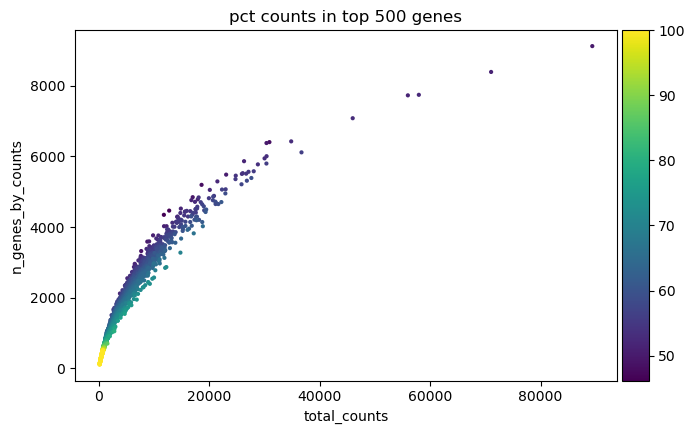

In [22]:
sc.pl.scatter(adata_rna, "total_counts", "n_genes_by_counts", color="pct_counts_in_top_500_genes")

In [23]:
sc.pp.filter_cells(adata_rna, min_genes=100)
sc.pp.filter_genes(adata_rna, min_cells=2)

In [24]:
# Saving count data
adata_rna.layers["counts"] = adata_rna.X.copy()

In [25]:
## Normalizing to median total counts
sc.pp.normalize_total(adata_rna)
# Logarithmize the data
sc.pp.log1p(adata_rna)

In [26]:
sc.pp.highly_variable_genes(adata_rna, n_top_genes=2000, flavor="seurat_v3")

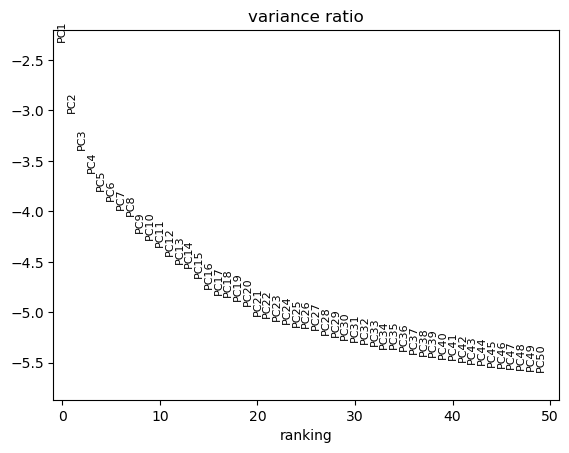

In [27]:
sc.tl.pca(adata_rna)
sc.pl.pca_variance_ratio(adata_rna, n_pcs=50, log=True)

In [28]:
sc.pp.neighbors(adata_rna)
sc.tl.umap(adata_rna)
# sc.pl.umap(
#     adata_rna,
#     color="celltype",
#     # Setting a smaller point size to get prevent overlap
#     size=20,
# )

In [29]:
sc.tl.leiden(adata_rna)
# sc.pl.umap(adata_rna, color=["leiden"])

In [30]:
# write adata_sc to disk

ad_rna_path = H5AD_DIR+"/c_sc_ad.h5ad"
adata_rna.write_h5ad(ad_rna_path)

In [31]:
cell_meta = pd.read_csv(CELLTYPE_FILE, sep="\t")

# Load ATAC data
atac = sc.read_mtx(ATAC_COUNTS_FILE).T
barcodes = pd.read_csv(ATAC_BARCODES_FILE, header=None)
atac.obs["barcode"] = barcodes[0].values

# Load peaks
peaks = pd.read_csv(ATAC_PEAKS_FILE, sep="\t", header=None, names=["chrom", "start", "end"])
peaks["peak_id"] = peaks["chrom"] + ":" + peaks["start"].astype(str) + "-" + peaks["end"].astype(str)
peaks.set_index("peak_id", inplace=True)
atac.var = peaks

# Since barcodes.txt.gz contains RNA barcodes, we need to map them to ATAC barcodes
# Create a mapping dictionary from RNA to ATAC
rna_to_atac = dict(zip(cell_meta["rna.bc"], cell_meta["atac.bc"]))

# Add ATAC barcode column based on RNA barcodes
atac.obs["atac_barcode"] = [rna_to_atac.get(bc, "unknown") for bc in atac.obs["barcode"]]

# Format ATAC barcodes for fragments file
import re
formatted_barcodes = []
for bc in atac.obs["atac_barcode"]:
    components = re.findall(r'(R\d+\.\d+|P\d+\.\d+)', bc)
    formatted_bc = ','.join(components)
    formatted_barcodes.append(formatted_bc)

# Add formatted barcodes
atac.obs["formatted_barcode"] = formatted_barcodes

# Set formatted barcodes as observation names
atac.obs_names = atac.obs["formatted_barcode"].values

# Add cell type information directly
atac.obs["celltype"] = atac.obs["barcode"].map(dict(zip(cell_meta["rna.bc"], cell_meta["celltype"])))

In [32]:
atac.obs.head()

,barcode,atac_barcode,formatted_barcode,celltype
"R1.01,R2.04,R3.55,P1.32",R1.01.R2.04.R3.55.P1.40,R1.01.R2.04.R3.55.P1.32,"R1.01,R2.04,R3.55,P1.32",EN07
"R1.01,R2.05,R3.35,P1.32",R1.01.R2.05.R3.35.P1.40,R1.01.R2.05.R3.35.P1.32,"R1.01,R2.05,R3.35,P1.32",P1
"R1.01,R2.08,R3.45,P1.31",R1.01.R2.08.R3.45.P1.39,R1.01.R2.08.R3.45.P1.31,"R1.01,R2.08,R3.45,P1.31",IN01
"R1.01,R2.08,R3.78,P1.31",R1.01.R2.08.R3.78.P1.39,R1.01.R2.08.R3.78.P1.31,"R1.01,R2.08,R3.78,P1.31",EN02
"R1.01,R2.09,R3.52,P1.32",R1.01.R2.09.R3.52.P1.40,R1.01.R2.09.R3.52.P1.32,"R1.01,R2.09,R3.52,P1.32",IN02


In [33]:
mu.atac.tl.locate_fragments(atac, str(ATAC_FRAGMENTS_FILE))

In [34]:
# Calculate general qc metrics using scanpy
sc.pp.calculate_qc_metrics(atac, percent_top=None, log1p=False, inplace=True)

# Rename columns
atac.obs.rename(
    columns={
        "n_genes_by_counts": "n_features_per_cell",
        "total_counts": "total_fragment_counts",
    },
    inplace=True,
)


# log-transform total counts and add as column
atac.obs["log_total_fragment_counts"] = np.log10(atac.obs["total_fragment_counts"])

In [35]:
# Calculate the nucleosome signal across cells
# set n=10e3*atac.n_obs for rough estimate but faster run time
mu.atac.tl.nucleosome_signal(atac, n=2000000)

Reading Fragments: 100%|██████████| 2000000/2000000 [00:07<00:00, 274375.09it/s]


<Axes: xlabel='nucleosome_signal', ylabel='Count'>

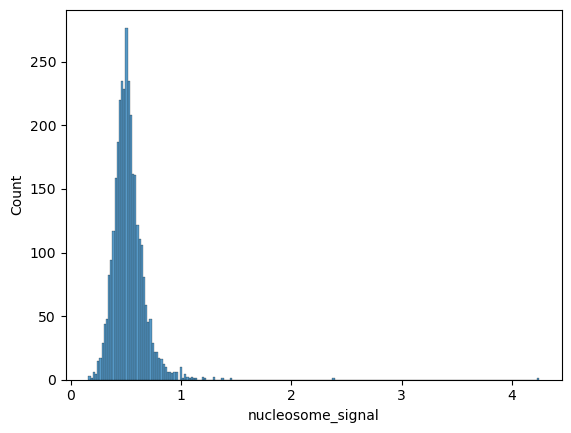

In [36]:
sns.histplot(atac.obs, x="nucleosome_signal")

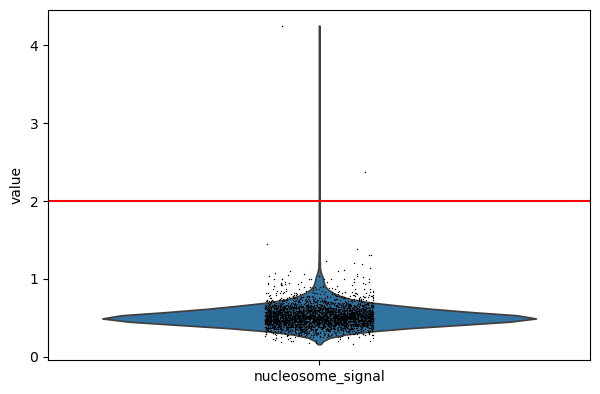

In [37]:
# nucleosome signal
p3 = sc.pl.violin(atac, "nucleosome_signal", show=False)
p3.axhline(y=2, c="red")

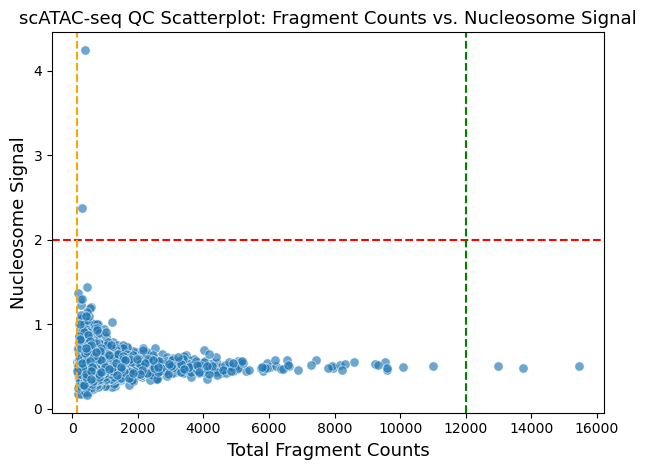

In [38]:
sns.scatterplot(data=atac.obs, x="total_fragment_counts", y="nucleosome_signal", alpha=0.65, s=45)
plt.axhline(2, color='red', linestyle='--')
plt.axvline(165, color='orange', linestyle='--')
plt.axvline(12000, color='green', linestyle='--')
plt.title("scATAC-seq QC Scatterplot: Fragment Counts vs. Nucleosome Signal", fontsize=13)
plt.xlabel("Total Fragment Counts", fontsize=13)
plt.ylabel("Nucleosome Signal", fontsize=13)
plt.tight_layout()
plt.show()


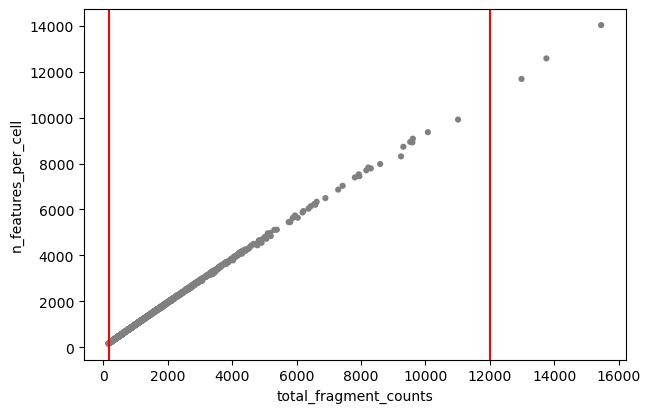

In [39]:
# Plot total counts of fragments & features colored by TSS score
p1 = sc.pl.scatter(
    atac,
    x="total_fragment_counts",
    y="n_features_per_cell",
    size=80,
    show=False,  # so that funstion output axis object where threshold line can be drawn.
)
p1.axvline(x=12000, c="red")  # Add vertical line
p1.axvline(x=165, c="red")  # Add vertical line

In [40]:
# Add group labels for above and below the nucleosome signal threshold
nuc_signal_threshold = 2
atac.obs["nuc_signal_filter"] = [
    "NS_FAIL" if ns > nuc_signal_threshold else "NS_PASS"
    for ns in atac.obs["nucleosome_signal"]
]

# Print number cells not passing nucleosome signal threshold
atac.obs["nuc_signal_filter"].value_counts()

nuc_signal_filter
NS_PASS    3291
NS_FAIL       2
Name: count, dtype: int64

In [41]:
pp = atac.copy()


In [42]:
print(f"Total number of cells: {pp.n_obs}")
mu.pp.filter_obs(
    pp,
    "total_fragment_counts",
    lambda x:  (x >= 165) &(x <= 12000),
)
print(f"Number of cells after filtering on total_fragment_counts: {pp.n_obs}")

Total number of cells: 3293
Number of cells after filtering on total_fragment_counts: 3288


In [43]:
atac_path = H5AD_DIR+"/c_atac_ad.h5ad"
pp.write_h5ad(atac_path)

In [44]:
mu.pp.filter_var(pp, "n_cells_by_counts", lambda x: x >= 2)

In [45]:
# Define the GTF URL
gtf_url = "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_mouse/release_M10/gencode.vM10.annotation.gtf.gz"

# Load and process the genes, excluding chrY
try:
    gene_coords_gencode = ga.load_gencode_gtf_genes(gtf_url, feature_type='gene', exclude_chroms=['chrY'])
except Exception as e:
    print(f"Failed to load or process GTF: {e}")

Successfully processed GTF from https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_mouse/release_M10/gencode.vM10.annotation.gtf.gz.
Number of 'gene' features found: 46870
Excluded chromosomes: ['chrY']


In [46]:
gene_coords_gencode = gene_coords_gencode[~gene_coords_gencode["chrom"].str.contains("chrY")]

In [47]:
# intersection with RNA data
common_genes_gencode = adata_rna.var_names.intersection(gene_coords_gencode.index)
print(f"\nNumber of common genes with RNA data (GENCODE M10): {len(common_genes_gencode)}")


Number of common genes with RNA data (GENCODE M10): 18696


In [48]:
adata_rna_annotated = adata_rna[:, list(common_genes_gencode)].copy()

In [49]:
gene_coords_gencode_reset = gene_coords_gencode.reset_index()

gene_coords_gencode_filtered = (
    gene_coords_gencode_reset
    .loc[gene_coords_gencode_reset['gene_name'].isin(common_genes_gencode)]
    .groupby(['gene_name', 'chrom'])
    .agg({
        'start': 'min',
        'end': 'max',
        'Strand': 'first',
        'gene_ids': 'first'
    })
    .reset_index()
)

gene_coords_gencode_filtered = gene_coords_gencode_filtered[
    ~((gene_coords_gencode_filtered['gene_name'] == 'Fth1') &
      (gene_coords_gencode_filtered['chrom'] == 'chr8'))
]

gene_coords_gencode_filtered = gene_coords_gencode_filtered.set_index('gene_name')

In [50]:
mdata = mu.MuData({'rna': adata_rna_annotated, 'atac': atac})

In [51]:
mu.atac.tl.initialise_default_files(mdata, path=MOUSE_BRAIN_DATA_DIR)

In [52]:
adata_atac_genes = mu.atac.tl.count_fragments_features(
    mdata,
    features=gene_coords_gencode_filtered,
    stranded=True,
    count_reads=False
)

  0%|          | 0/18696 [00:00<?, ?it/s]

100%|██████████| 18696/18696 [01:11<00:00, 260.15it/s]


In [53]:
sc.pp.filter_genes(adata_atac_genes, min_cells=2)

In [54]:
sc.pp.normalize_total(adata_atac_genes)
# Logarithmize the data
sc.pp.log1p(adata_atac_genes)

In [71]:
adata_atac_genes.write_h5ad(str(H5AD_DIR+"/c_atac_genes_ad.h5ad"))

In [55]:
# Ensure gene_coords_gencode_filtered has the 'interval' column if it doesn't already
if 'interval' not in gene_coords_gencode_filtered.columns:
    gene_coords_gencode_filtered['interval'] = \
        gene_coords_gencode_filtered['chrom'].astype(str) + ':' + \
        gene_coords_gencode_filtered['start'].astype(str) + '-' + \
        gene_coords_gencode_filtered['end'].astype(str)

# Ensure the index names match before merging
mdata['rna'].var.index.name = 'gene_name'
gene_coords_gencode_filtered.index.name = 'gene_name'


# Select only the necessary columns from gene_coords_gencode_filtered for the merge
gene_info_for_merge = gene_coords_gencode_filtered[['chrom', 'start', 'end', 'Strand', 'interval', 'gene_ids']]

# Merge the gene annotation information into the .var DataFrame of the RNA modality
mdata['rna'].var = mdata['rna'].var.merge(
    gene_info_for_merge,
    left_index=True,
    right_index=True,
    how='left' # Use a left merge to keep all genes in mdata['rna'].var
)

In [ ]:
ccres = pd.read_csv("luisthesis/data/mm10-cCREs.bed", sep="\t", header=None)
# candidata cis-Regulatory elements

In [57]:
ccres['intervals'] = ccres.iloc[:,0]+":"+ccres.iloc[:,1].astype(str)+"-"+ccres.iloc[:,2].astype(str)

In [58]:
ccres= ccres.iloc[:,range(3,7)]

In [59]:
ccres.head()

,3,4,5,intervals
0,EM10D1036230,EM10E0932225,CA-CTCF,chr1:3012681-3012836
1,EM10D1036232,EM10E1235196,CA,chr1:3035821-3035995
2,EM10D1036235,EM10E1235197,CA,chr1:3059627-3059790
3,EM10D1036236,EM10E1235198,CA,chr1:3062547-3062749
4,EM10D1036237,EM10E1235199,CA,chr1:3062789-3063138


In [60]:
ccres.columns = ['ens1', 'ens2', 'CRE', 'Intervals']

In [ ]:
share = mdata
share['atac'].uns['atac'] = {'CREs': ccres}

In [71]:
share['rna'].obs

,celltype,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,n_genes,leiden
R1.01.R2.04.R3.55.P1.40,EN07,1204,7.094235,2377,7.774015,28.901977,39.419436,51.535549,70.382836,1204,12
R1.01.R2.05.R3.35.P1.40,P1,4347,8.377471,11771,9.373479,16.719055,22.997196,31.169824,46.164302,4347,7
R1.01.R2.08.R3.45.P1.39,IN01,405,6.006353,507,6.230481,26.824458,39.842209,59.566075,100.000000,405,18
R1.01.R2.08.R3.78.P1.39,EN02,2154,7.675546,4501,8.412277,20.950900,29.126861,39.568985,57.564986,2154,25
R1.01.R2.09.R3.52.P1.40,IN02,3177,8.064007,9957,9.206132,25.640253,34.799638,44.752435,60.018078,3177,3
...,...,...,...,...,...,...,...,...,...,...,...
R1.96.R2.79.R3.15.P1.39,MX,1465,7.290293,2989,8.003029,29.274005,38.006022,48.845768,67.714955,1465,19
R1.96.R2.84.R3.71.P1.39,EN02,1323,7.188413,2523,7.833600,27.070947,36.464526,48.394768,67.380103,1323,4
R1.96.R2.88.R3.65.P1.39,IN01,2383,7.776535,4955,8.508354,19.858729,28.052472,37.901110,55.519677,2383,0
R1.96.R2.90.R3.91.P1.40,EN09,1239,7.122867,2524,7.833996,31.022187,41.125198,52.892235,70.721078,1239,14


In [77]:
share['rna'].var

,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,highly_variable,highly_variable_rank,means,variances,variances_norm,chrom,start,end,Strand,interval,gene_ids
gene_name,,,,,,,,,,,,,,,,,,
0610007P14Rik,194,0.067719,0.065525,94.108715,223,5.411646,194,False,NaN,0.029704,0.019572,0.904707,chr12,85815448,85824550,-,chr12:85815448-85824550,ENSMUSG00000021252.11
0610009B22Rik,14,0.004251,0.004242,99.574856,14,2.708050,14,False,NaN,0.001645,0.000823,0.701482,chr11,51685386,51688874,-,chr11:51685386-51688874,ENSMUSG00000007777.9
0610009L18Rik,12,0.003644,0.003637,99.635591,12,2.564949,12,False,NaN,0.001794,0.001327,1.031901,chr11,120348678,120351190,+,chr11:120348678-120351190,ENSMUSG00000043644.4
0610009O20Rik,192,0.064075,0.062106,94.169450,211,5.356586,192,False,NaN,0.030514,0.022809,1.026816,chr18,38250249,38262629,+,chr18:38250249-38262629,ENSMUSG00000024442.5
0610010F05Rik,1270,0.632858,0.490332,61.433343,2084,7.642524,1270,False,NaN,0.271568,0.163015,0.913968,chr11,23564961,23633639,-,chr11:23564961-23633639,ENSMUSG00000042208.15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zyg11b,980,0.417249,0.348717,70.239903,1374,7.226209,980,False,NaN,0.187406,0.117835,0.928977,chr4,108229724,108301096,-,chr4:108229724-108301096,ENSMUSG00000034636.9
Zyx,74,0.022776,0.022520,97.752809,75,4.330733,74,False,NaN,0.009638,0.006838,0.962656,chr6,42349630,42360213,+,chr6:42349630-42360213,ENSMUSG00000029860.16
Zzef1,1380,0.731552,0.549018,58.092924,2409,7.787382,1380,False,NaN,0.308312,0.186558,0.932785,chr11,72796226,72927120,+,chr11:72796226-72927120,ENSMUSG00000055670.14


In [72]:
share['atac'].obs

,barcode,atac_barcode,formatted_barcode,celltype,n_features_per_cell,total_fragment_counts,log_total_fragment_counts,nucleosome_signal,nuc_signal_filter
"R1.01,R2.04,R3.55,P1.32",R1.01.R2.04.R3.55.P1.40,R1.01.R2.04.R3.55.P1.32,"R1.01,R2.04,R3.55,P1.32",EN07,756,762.0,2.881955,0.417910,NS_PASS
"R1.01,R2.05,R3.35,P1.32",R1.01.R2.05.R3.35.P1.40,R1.01.R2.05.R3.35.P1.32,"R1.01,R2.05,R3.35,P1.32",P1,8313,9245.0,3.965907,0.533446,NS_PASS
"R1.01,R2.08,R3.45,P1.31",R1.01.R2.08.R3.45.P1.39,R1.01.R2.08.R3.45.P1.31,"R1.01,R2.08,R3.45,P1.31",IN01,386,392.0,2.593286,0.705882,NS_PASS
"R1.01,R2.08,R3.78,P1.31",R1.01.R2.08.R3.78.P1.39,R1.01.R2.08.R3.78.P1.31,"R1.01,R2.08,R3.78,P1.31",EN02,1561,1589.0,3.201124,0.506849,NS_PASS
"R1.01,R2.09,R3.52,P1.32",R1.01.R2.09.R3.52.P1.40,R1.01.R2.09.R3.52.P1.32,"R1.01,R2.09,R3.52,P1.32",IN02,2451,2521.0,3.401573,0.378924,NS_PASS
...,...,...,...,...,...,...,...,...,...
"R1.96,R2.79,R3.15,P1.31",R1.96.R2.79.R3.15.P1.39,R1.96.R2.79.R3.15.P1.31,"R1.96,R2.79,R3.15,P1.31",MX,860,875.0,2.942008,0.437126,NS_PASS
"R1.96,R2.84,R3.71,P1.31",R1.96.R2.84.R3.71.P1.39,R1.96.R2.84.R3.71.P1.31,"R1.96,R2.84,R3.71,P1.31",EN02,578,586.0,2.767898,0.348837,NS_PASS
"R1.96,R2.88,R3.65,P1.31",R1.96.R2.88.R3.65.P1.39,R1.96.R2.88.R3.65.P1.31,"R1.96,R2.88,R3.65,P1.31",IN01,2408,2465.0,3.391817,0.571956,NS_PASS
"R1.96,R2.90,R3.91,P1.32",R1.96.R2.90.R3.91.P1.40,R1.96.R2.90.R3.91.P1.32,"R1.96,R2.90,R3.91,P1.32",EN09,1104,1115.0,3.047275,0.473684,NS_PASS


In [78]:
share["atac"].var

,chrom,start,end,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
peak_id,,,,,,,
chr1:3042898-3043397,chr1,3042898,3043397,1,0.000304,99.969633,1.0
chr1:3094912-3095411,chr1,3094912,3095411,7,0.002429,99.787428,8.0
chr1:3113444-3113943,chr1,3113444,3113943,2,0.000607,99.939265,2.0
chr1:3119743-3120242,chr1,3119743,3120242,23,0.007288,99.301549,24.0
chr1:3120409-3120908,chr1,3120409,3120908,25,0.007592,99.240814,25.0
...,...,...,...,...,...,...,...
chrX:170007011-170007510,chrX,170007011,170007510,2,0.000607,99.939265,2.0
chrX:170673169-170673668,chrX,170673169,170673668,3,0.000911,99.908898,3.0
chrX:170674252-170674751,chrX,170674252,170674751,7,0.002429,99.787428,8.0


In [76]:
share["atac"].uns

OrderedDict([('files',
              {'fragments': 'luisthesis/data/shareseq//GSM4156599_brain.atac.fragments.sorted.bed.gz'}),
             ('atac',
              {'CREs':                 ens1          ens2         CRE               Intervals
               0       EM10D1036230  EM10E0932225     CA-CTCF    chr1:3012681-3012836
               1       EM10D1036232  EM10E1235196          CA    chr1:3035821-3035995
               2       EM10D1036235  EM10E1235197          CA    chr1:3059627-3059790
               3       EM10D1036236  EM10E1235198          CA    chr1:3062547-3062749
               4       EM10D1036237  EM10E1235199          CA    chr1:3062789-3063138
               ...              ...           ...         ...                     ...
               926838  EM10D2262503  EM10E1732271          CA  chrY:90743615-90743799
               926839  EM10D2262504  EM10E0932221  CA-H3K4me3  chrY:90743873-90744156
               926840  EM10D3427103  EM10E1732272        dELS  chrY:

In [ ]:
share.write("luisthesis/data/share_pp.h5mu")